# ORI 2026 - EKSPERIMENT 1: PREDVIĐANJE CENA (V2 — poboljšano)
## 1-1, 1-2, 1-3 (a/b/c podslučajevi) — sve regresija

Ovaj notebook:
- ✅ Učitava CSV fajlove (Date, Price, Open, High, Low, Vol.)
- ✅ Izveštaj o nedostajućim vrednostima po paru
- ✅ Indikatori pomoću `ta` paketa (SMA, EMA, ROC, RSI, MACD, STD, ATR)
- ✅ Eksperiment 1-1: cene / indikatori / cene+indikatori → cena(t+1,t+5,t+10)
- ✅ Eksperiment 1-2: + ROC od ulaznih varijabli → cena(t+1,t+3,t+5,t+10)
- ✅ Eksperiment 1-3: + ROC i SMA od ulaznih varijabli → cena(t+1,t+3,t+5,t+10)
- ✅ MLP regresor za svaku kombinaciju (par × podslučaj × horizont)
- ✅ Print svih rezultata + jedna zbirna Excel tabela na kraju

### 🆕 Izmene u V2 (popravka loših rezultata za podslučaje b/c):
1. **Dijagnostička ćelija** — pokazuje brojkama koliko su lagovani indikatori
   bili međusobno korelirani (multikolinearnost), pre i posle popravke.
2. **Manje lagova za indikatore** (2 umesto 5) — indikatori su već "spori"
   signali, previše lagova pravi desetine skoro identičnih kolona.
3. **RobustScaler za podslučaje b/c** — manje osetljiv na outliere u
   indikatorima (MACD, STD, ATR imaju teže repove raspodele od cene).
4. **Veći `max_iter` (2000) i `n_iter_no_change` (25)** — veći feature setovi
   trebaju više iteracija da konvergiraju; loguje se da li je model
   stigao do konvergencije ili se zaglavio na max_iter.
5. **L2 regularizacija (`alpha=0.001`)** — smanjuje overfit na korelirane feature-e.
6. **Dijagnostički ispis po modelu**: broj feature-a, broj iteracija, konvergencija.

In [15]:
import pandas as pd
import numpy as np
import os
import glob
import warnings
from math import sqrt

warnings.filterwarnings('ignore')

possible_dirs = [".", "data", "./data", "../data"]
INPUT_DIR = ".."

for dir_path in possible_dirs:
    if os.path.exists(dir_path):
        csv_files = glob.glob(os.path.join(dir_path, "*_Data.csv"))
        if csv_files and len(csv_files) >=5:
            INPUT_DIR = dir_path
            break

print(f"✓ CSV fajlovi pronađeni u: {INPUT_DIR}")
print(f"✓ Sve biblioteke učitane!")

✓ CSV fajlovi pronađeni u: data
✓ Sve biblioteke učitane!


## 📋 FAZA 1: Priprema podataka

In [16]:
def load_csv(path):
    df = pd.read_csv(path, encoding="utf-8-sig")
    df.columns = [c.strip().strip('"') for c in df.columns]
    return df

def clean_numeric_column(series):
    """Konvertuje string kolonu (zarezi/procenti/K,M,B sufiksi) u numeričku."""
    s = series.astype(str).str.replace(",", "", regex=False)
    s = s.str.replace("%", "", regex=False)

    def parse_suffix(val):
        if not isinstance(val, str):
            return np.nan if pd.isna(val) else float(val)
        val = val.strip()
        if val in ("", "nan", "None", "-"):
            return np.nan
        multiplier = 1
        if val.endswith("K"):
            multiplier, val = 1_000, val[:-1]
        elif val.endswith("M"):
            multiplier, val = 1_000_000, val[:-1]
        elif val.endswith("B"):
            multiplier, val = 1_000_000_000, val[:-1]
        try:
            return float(val) * multiplier
        except ValueError:
            return np.nan

    return s.apply(parse_suffix)

csv_files = sorted(glob.glob(os.path.join(INPUT_DIR, "*_Data.csv")))
print(f"Pronađeno {len(csv_files)} CSV fajlova:\n")

all_data = []
missing_report = []

for path in csv_files:
    pair_name = os.path.basename(path).replace("_Data.csv", "")
    df_raw = load_csv(path)

    df_raw["Date"] = pd.to_datetime(df_raw["Date"], format="%m/%d/%Y", errors="coerce")

    numeric_cols = [c for c in ["Price", "Open", "High", "Low", "Change %"] if c in df_raw.columns]
    for col in numeric_cols:
        df_raw[col] = clean_numeric_column(df_raw[col])

    total_rows = len(df_raw)
    cols_to_check = ["Date"] + numeric_cols
    missing_counts = df_raw[cols_to_check].isna().sum()
    missing_pct = (missing_counts / total_rows * 100).round(2)

    report_row = {"Pair": pair_name, "Total_Rows": total_rows}
    for col in cols_to_check:
        report_row[f"{col}_missing_%"] = missing_pct[col]
    missing_report.append(report_row)

    keep_cols = ["Date"] + numeric_cols
    df = df_raw[keep_cols].dropna(subset=["Date", "Price"])
    df["Pair"] = pair_name

    all_data.append(df)
    print(f"  ✓ {pair_name:10s}: {len(df)} redova (od {total_rows} ukupno)")

currency_all = pd.concat(all_data, ignore_index=True)
currency_all = currency_all.sort_values(["Pair", "Date"]).reset_index(drop=True)

print(f"\n✓ Ukupno: {len(currency_all)} redova za {currency_all['Pair'].nunique()} parova")

Pronađeno 6 CSV fajlova:

  ✓ EURUSD    : 2610 redova (od 2610 ukupno)
  ✓ USDCAD    : 2610 redova (od 2610 ukupno)
  ✓ USDCHF    : 2610 redova (od 2610 ukupno)
  ✓ USDCNY    : 2611 redova (od 2611 ukupno)
  ✓ USDGBP    : 2610 redova (od 2610 ukupno)
  ✓ USDJPY    : 2610 redova (od 2610 ukupno)

✓ Ukupno: 15661 redova za 6 parova


### 📊 Izveštaj o nedostajućim vrednostima po valutnom paru

In [17]:
missing_df = pd.DataFrame(missing_report)
print("="*80)
print("UDEO NEDOSTAJUĆIH VREDNOSTI PO PARU (%)")
print("="*80 + "\n")
print(missing_df.to_string(index=False))

UDEO NEDOSTAJUĆIH VREDNOSTI PO PARU (%)

  Pair  Total_Rows  Date_missing_%  Price_missing_%  Open_missing_%  High_missing_%  Low_missing_%  Change %_missing_%
EURUSD        2610             0.0              0.0             0.0             0.0            0.0                 0.0
USDCAD        2610             0.0              0.0             0.0             0.0            0.0                 0.0
USDCHF        2610             0.0              0.0             0.0             0.0            0.0                 0.0
USDCNY        2611             0.0              0.0             0.0             0.0            0.0                 0.0
USDGBP        2610             0.0              0.0             0.0             0.0            0.0                 0.0
USDJPY        2610             0.0              0.0             0.0             0.0            0.0                 0.0


## 🔧 FAZA 2: Inženjering indikatora (paket `ta`)

In [18]:
from ta.trend import SMAIndicator, EMAIndicator, MACD
from ta.momentum import ROCIndicator, RSIIndicator
from ta.volatility import AverageTrueRange

INDICATOR_COLS = ["SMA_14", "EMA_14", "ROC_14", "RSI_14", "MACD", "MACD_Signal", "MACD_Hist", "STD_14", "ATR_14"]

def calculate_indicators(pair_df):
    close = pair_df["Price"]
    high = pair_df["High"] if "High" in pair_df.columns else close
    low = pair_df["Low"] if "Low" in pair_df.columns else close

    out = pd.DataFrame(index=pair_df.index)
    out["SMA_14"] = SMAIndicator(close=close, window=14).sma_indicator()
    out["EMA_14"] = EMAIndicator(close=close, window=14).ema_indicator()
    out["ROC_14"] = ROCIndicator(close=close, window=14).roc()
    out["RSI_14"] = RSIIndicator(close=close, window=14).rsi()

    macd = MACD(close=close, window_slow=26, window_fast=12, window_sign=9)
    out["MACD"] = macd.macd()
    out["MACD_Signal"] = macd.macd_signal()
    out["MACD_Hist"] = macd.macd_diff()

    out["STD_14"] = close.rolling(14).std()
    out["ATR_14"] = AverageTrueRange(high=high, low=low, close=close, window=14).average_true_range()

    return out

print("Računanje indikatora pomoću `ta` paketa...\n")

all_features = []
for pair_name in currency_all["Pair"].unique():
    pair_data = currency_all[currency_all["Pair"] == pair_name].sort_values("Date").reset_index(drop=True)
    indicators = calculate_indicators(pair_data)
    indicators["Date"] = pair_data["Date"].values
    indicators["Price"] = pair_data["Price"].values
    indicators["Pair"] = pair_name
    all_features.append(indicators)
    print(f"  ✓ {pair_name}: {len(indicators)} redova")

features = pd.concat(all_features, ignore_index=True)
features = features[["Pair", "Date", "Price"] + INDICATOR_COLS]

print(f"\n✓ Shape: {features.shape}")

Računanje indikatora pomoću `ta` paketa...

  ✓ EURUSD: 2610 redova
  ✓ USDCAD: 2610 redova
  ✓ USDCHF: 2610 redova
  ✓ USDCNY: 2611 redova
  ✓ USDGBP: 2610 redova
  ✓ USDJPY: 2610 redova

✓ Shape: (15661, 12)


## 🧪 FAZA 3: Priprema za Eksperiment 1 (ROC/SMA generatori + targeti)

In [19]:
def add_roc(df, cols, n):
    """ROC(n) za svaku kolonu u cols: (x[t] - x[t-n]) / x[t-n] * 100.
    Inf vrednosti (kada je x[t-n] blizu nule, npr. MACD_Hist oko 0) se
    sanitizuju u NaN da ne probiju MLP regresor."""
    out = pd.DataFrame(index=df.index)
    for c in cols:
        roc = df[c].pct_change(n) * 100
        roc = roc.replace([np.inf, -np.inf], np.nan)
        out[f"ROC{n}_{c}"] = roc
    return out

def add_sma(df, cols, n):
    """SMA(n) za svaku kolonu u cols"""
    out = pd.DataFrame(index=df.index)
    for c in cols:
        out[f"SMA{n}_{c}"] = df[c].rolling(n).mean()
    return out

def add_price_targets(df, horizons):
    """Dodaj kolone Target_t+h = Price pomeren unapred za h"""
    out = pd.DataFrame(index=df.index)
    for h in horizons:
        out[f"Target_t+{h}"] = df["Price"].shift(-h)
    return out

print("✓ Helper funkcije definisane (ROC, SMA, target generatori)")

✓ Helper funkcije definisane (ROC, SMA, target generatori)


## 🧠 FAZA 4: MLP Regresor — definicija eksperimenta

In [20]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

N_LAGS = 5
N_LAGS_INDICATORS = 2  # MANJE lagova za indikatore (5 lagova je pravilo previse korelirane kolone)
TEST_SIZE = 0.2

MLP_PARAMS = {
    'hidden_layer_sizes': (32, 16),
    'activation': 'relu',
    'solver': 'adam',
    'max_iter': 2000,          # povećano sa 300 — veći feature setovi (b,c) trebaju više iteracija
    'early_stopping': True,
    'n_iter_no_change': 25,    # povećano sa default 10 — manje agresivno prevremeno gašenje
    'alpha': 0.001,            # L2 regularizacija — smanjuje overfit na koreliranim feature-ima
    'random_state': 42,
    'verbose': 0
}

def run_regression(X, y, test_size=TEST_SIZE, dates=None, scaler_type='standard'):
    """Treniraj MLPRegressor i vrati metrike + predikcije + dijagnostiku konvergencije.
    X, y su već usklađeni i bez NaN. `dates` (opciono) su datumi istog
    poravnanja kao X/y, koriste se za x-osu grafova.
    scaler_type: 'standard' ili 'robust' (robust je manje osetljiv na outliere
    u indikatorima kao MACD/STD koji imaju teže repove raspodele od same cene)."""
    split_idx = int(len(X) * (1 - test_size))
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]

    if len(X_train) < 30 or len(X_test) < 10:
        return None

    Scaler = RobustScaler if scaler_type == 'robust' else StandardScaler
    scaler = Scaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

    model = MLPRegressor(**MLP_PARAMS)
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    test_dates = dates[split_idx:] if dates is not None else None
    converged = model.n_iter_ < MLP_PARAMS['max_iter']  # False = zaglavio na max_iter, nije stigao do konvergencije

    return {
        "MAE": mae, "RMSE": rmse, "R2": r2,
        "Train_Size": len(X_train), "Test_Size": len(X_test),
        "y_test": y_test, "y_pred": y_pred, "test_dates": test_dates,
        "n_iter": model.n_iter_, "converged": converged, "n_features": X.shape[1],
    }

print(f"✓ MLP Parametri: {MLP_PARAMS}")

✓ MLP Parametri: {'hidden_layer_sizes': (32, 16), 'activation': 'relu', 'solver': 'adam', 'max_iter': 2000, 'early_stopping': True, 'n_iter_no_change': 25, 'alpha': 0.001, 'random_state': 42, 'verbose': 0}


## 🔍 FAZA 4b: Dijagnostika — zašto su indikatori (b/c) radili lošije od cena (a)?

Provera multikolinearnosti: ako su lagovane kolone indikatora skoro identične
jedna drugoj (visoka korelacija), MLP teže izvlači signal iz njih nego iz
čistih lagova cene. Ovo objašnjava zašto je `b) indikatori` davao niži/negativan R²
u prethodnoj verziji notebook-a (5 lagova po indikatoru → previše redundantnih kolona).

In [21]:
sample_pair = features['Pair'].unique()[0]
pdf_diag = features[features['Pair'] == sample_pair].sort_values('Date').reset_index(drop=True)

# Stara verzija: 5 lagova po indikatoru
old_indicator_lags = pd.DataFrame(index=pdf_diag.index)
for col in INDICATOR_COLS:
    old_indicator_lags[col] = pdf_diag[col]
    for lag in range(1, 6):
        old_indicator_lags[f'{col}_lag{lag}'] = pdf_diag[col].shift(lag)

# Nova verzija: 2 laga po indikatoru
new_indicator_lags = pd.DataFrame(index=pdf_diag.index)
for col in INDICATOR_COLS:
    new_indicator_lags[col] = pdf_diag[col]
    for lag in range(1, N_LAGS_INDICATORS + 1):
        new_indicator_lags[f'{col}_lag{lag}'] = pdf_diag[col].shift(lag)

def corr_stats(df):
    """Statistika apsolutnih parnih korelacija (van dijagonale).
    Max je gotovo uvek ~1.0 (susedni lagovi su trivijalno slični) — bitnija je
    PROSEČNA/MEDIJALNA korelacija, koja pokazuje koliko je CELOKUPAN feature
    set redundantan, ne samo najgori par."""
    corr = df.dropna().corr().abs().to_numpy(copy=True)
    n = corr.shape[0]
    mask = ~np.eye(n, dtype=bool)
    off_diag = corr[mask]
    # >0.8 se smatra visokom korelacijom (pravilo struke)
    pct_high = (off_diag > 0.8).mean() * 100
    return off_diag.mean(), np.median(off_diag), pct_high, n

old_mean, old_median, old_pct_high, old_n = corr_stats(old_indicator_lags)
new_mean, new_median, new_pct_high, new_n = corr_stats(new_indicator_lags)

print(f"Primer par: {sample_pair}\n")
print(f"{'':30s} {'Kolona':>8s} {'Prosek|r|':>10s} {'Medijana|r|':>12s} {'%parova |r|>0.8':>16s}")
print(f"{'STARO (5 lagova/indikator)':30s} {old_n:>8d} {old_mean:>10.3f} {old_median:>12.3f} {old_pct_high:>15.1f}%")
print(f"{'NOVO  (2 laga/indikator)':30s} {new_n:>8d} {new_mean:>10.3f} {new_median:>12.3f} {new_pct_high:>15.1f}%")
print(f"\n→ Broj feature kolona smanjen sa {old_n} na {new_n} ({100*(1-new_n/old_n):.0f}% manje).")
print(f"→ Udeo VISOKO koreliranih parova (|r|>0.8) {'smanjen' if new_pct_high < old_pct_high else 'nepromenjen/povećan'}: "
      f"{old_pct_high:.1f}% → {new_pct_high:.1f}%")
print(f"\nNapomena: pojedinačni max (npr. SMA_14 vs SMA_14_lag1) ostaje ~1.0 u oba")
print(f"slučaja — to je očekivano i nije problem sam po sebi. Problem je KOLIČINA")
print(f"redundantnih kolona koje MLP mora da obradi; manje lagova = manje šuma.")

Primer par: EURUSD

                                 Kolona  Prosek|r|  Medijana|r|  %parova |r|>0.8
STARO (5 lagova/indikator)           54      0.349        0.180            16.0%
NOVO  (2 laga/indikator)             27      0.348        0.172            16.2%

→ Broj feature kolona smanjen sa 54 na 27 (50% manje).
→ Udeo VISOKO koreliranih parova (|r|>0.8) nepromenjen/povećan: 16.0% → 16.2%

Napomena: pojedinačni max (npr. SMA_14 vs SMA_14_lag1) ostaje ~1.0 u oba
slučaja — to je očekivano i nije problem sam po sebi. Problem je KOLIČINA
redundantnih kolona koje MLP mora da obradi; manje lagova = manje šuma.


## 🚀 FAZA 5: EKSPERIMENT 1-1
### a) cene → cena(t+1,t+5,t+10) | b) indikatori → cena(...) | c) cene+indikatori → cena(...)

In [22]:
HORIZONS_1_1 = [1, 5, 10]
results_all = []
predictions_1_1 = {}  # {(pair, subcase, horizon): {"dates":..., "y_test":..., "y_pred":...}}

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    # Lagovane cene (za podslučaj a i c) - ostaje 5 lagova, čista serija sa nizom autokorelacijom
    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)

    # Lagovani indikatori (za podslučaj b i c) - SMANJENO na N_LAGS_INDICATORS (2) lagova.
    # Indikatori su već "spori"/smoothed signali (SMA_14, EMA_14...), pa 5 lagova svakog
    # pravi desetine skoro identičnih kolona (multikolinearnost) koje zbunjuju MLP.
    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)

    targets = add_price_targets(pdf, HORIZONS_1_1)

    feature_sets = {
        'a) cene': (price_lags, 'standard'),
        'b) indikatori': (indicator_lags, 'robust'),
        'c) cene+indikatori': (pd.concat([price_lags, indicator_lags], axis=1), 'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets.items():
        for h in HORIZONS_1_1:
            combo = pd.concat([X_df, targets[[f'Target_t+{h}']], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50:
                continue
            X = combo[X_df.columns].values
            y = combo[f'Target_t+{h}'].values
            dates_arr = combo['Date'].values

            metrics = run_regression(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None:
                continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[1-1 {subcase} | {pair_name} | t+{h}] MAE={metrics['MAE']:.5f} RMSE={metrics['RMSE']:.5f} "
                  f"R2={metrics['R2']:.4f} | feat={metrics['n_features']} iter={metrics['n_iter']} {conv_flag}")

            results_all.append({
                'Experiment': '1-1', 'Subcase': subcase, 'Pair': pair_name,
                'Horizon': f't+{h}', 'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'],
                'R2': metrics['R2'], 'Train_Size': metrics['Train_Size'], 'Test_Size': metrics['Test_Size'],
                'N_Features': metrics['n_features'], 'N_Iter': metrics['n_iter'], 'Converged': metrics['converged'],
            })


            predictions_1_1[(pair_name, subcase, h)] = {
                'dates': metrics['test_dates'],
                'y_test': metrics['y_test'],
                'y_pred': metrics['y_pred'],
            }

print("\n✓ Eksperiment 1-1 završen.")

[1-1 c) cene+indikatori | USDJPY | t+10] MAE=2.53686 RMSE=3.37201 R2=0.5069 | feat=32 iter=623 ✓konv.

✓ Eksperiment 1-1 završen.


## 📈 FAZA 5b: Grafovi predikcija — Eksperiment 1-1
### Predicted vs Actual cena na test skupu, za svaki par (grid: redovi=a/b/c, kolone=t+1/t+5/t+10)

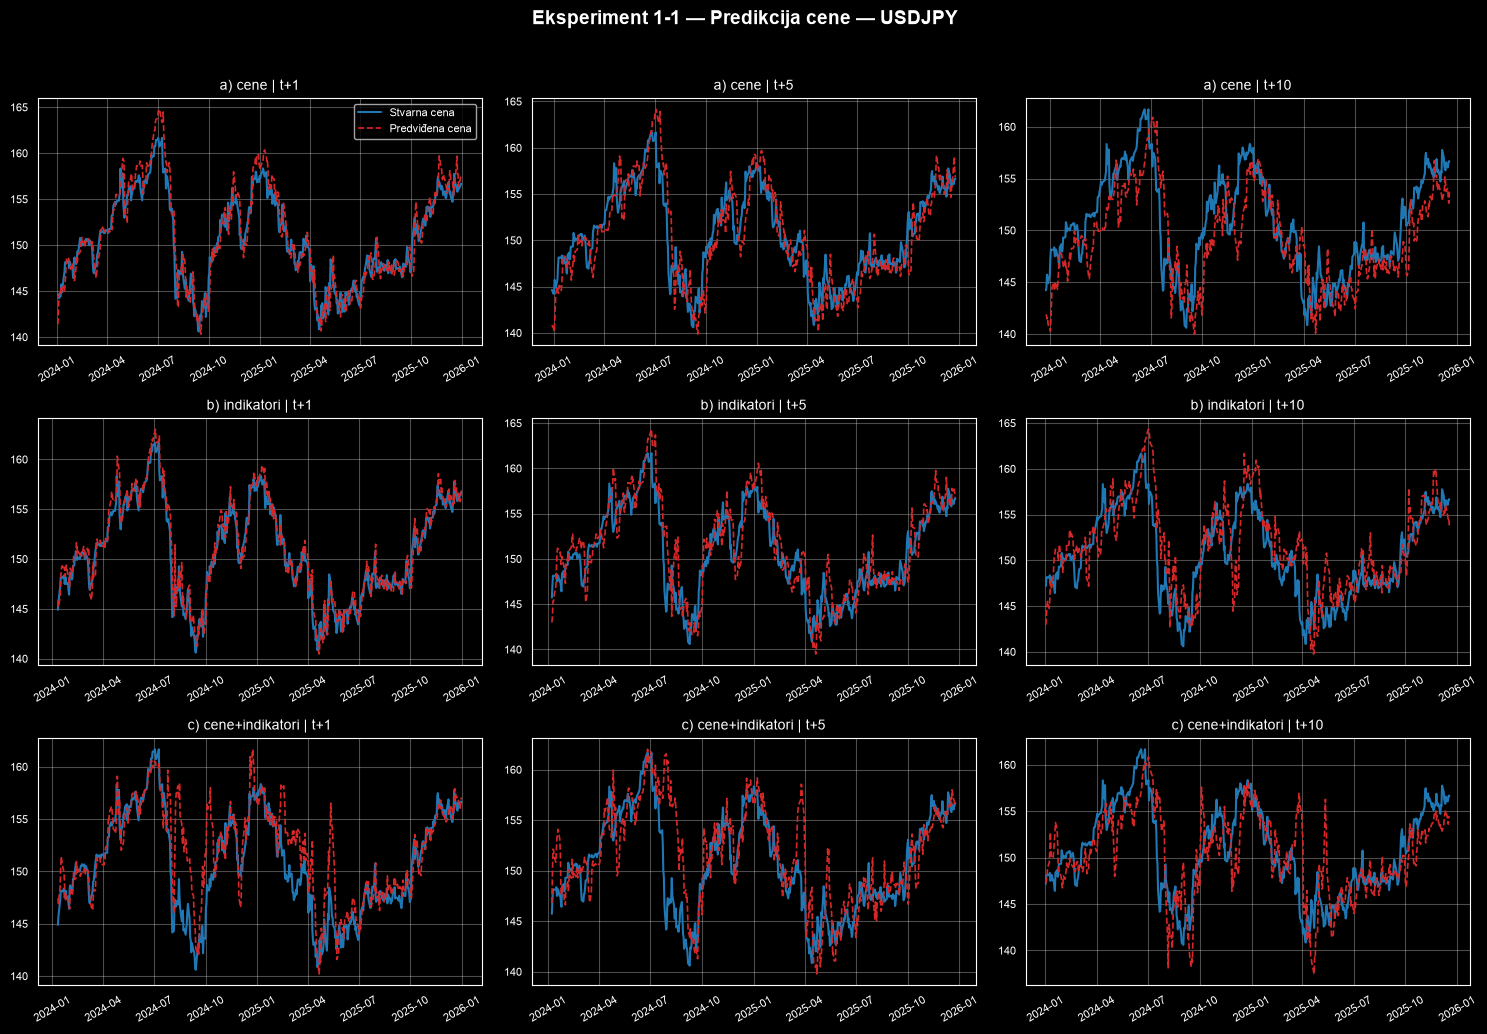

In [23]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

SUBCASES_1_1 = ['a) cene', 'b) indikatori', 'c) cene+indikatori']

for pair_name in features['Pair'].unique():
    fig, axes = plt.subplots(len(SUBCASES_1_1), len(HORIZONS_1_1),
                              figsize=(5 * len(HORIZONS_1_1), 3.5 * len(SUBCASES_1_1)),
                              squeeze=False)
    fig.suptitle(f"Eksperiment 1-1 — Predikcija cene — {pair_name}", fontsize=14, fontweight='bold')

    for row, subcase in enumerate(SUBCASES_1_1):
        for col, h in enumerate(HORIZONS_1_1):
            ax = axes[row][col]
            key = (pair_name, subcase, h)

            if key not in predictions_1_1:
                ax.set_title(f"{subcase} | t+{h} (nema podataka)")
                ax.axis('off')
                continue

            data = predictions_1_1[key]
            dates_plot = data['dates']
            y_test = data['y_test']
            y_pred = data['y_pred']

            ax.plot(dates_plot, y_test, label='Stvarna cena', color='#1f77b4', linewidth=1.5)
            ax.plot(dates_plot, y_pred, label='Predviđena cena', color='#d62728', linewidth=1.2, linestyle='--')

            ax.set_title(f"{subcase} | t+{h}", fontsize=10)
            ax.xaxis.set_major_locator(mdates.AutoDateLocator())
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
            ax.tick_params(axis='x', rotation=30, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)
            ax.grid(alpha=0.3)
            if row == 0 and col == 0:
                ax.legend(fontsize=8, loc='best')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()



## 🚀 FAZA 6: EKSPERIMENT 1-2
### + ROC od ulaznih varijabli → cena(t+1,t+3,t+5,t+10)

In [24]:
HORIZONS_1_2 = [1, 3, 5, 10]

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)
    roc_price = add_roc(pdf, ['Price'], 14)  # ROC od CENA

    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)
    roc_indicators = add_roc(pdf, INDICATOR_COLS, 14)  # ROC od INDIKATORA

    targets = add_price_targets(pdf, HORIZONS_1_2)

    feature_sets = {
        'a) cene+ROC(cena)': (pd.concat([price_lags, roc_price], axis=1), 'standard'),
        'b) indikatori+ROC(ind)': (pd.concat([indicator_lags, roc_indicators], axis=1), 'robust'),
        'c) cene+ind+ROC(oba)': (pd.concat([price_lags, roc_price, indicator_lags, roc_indicators], axis=1), 'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets.items():
        for h in HORIZONS_1_2:
            combo = pd.concat([X_df, targets[[f'Target_t+{h}']]], axis=1).dropna()
            if len(combo) < 50:
                continue
            X = combo[X_df.columns].values
            y = combo[f'Target_t+{h}'].values

            metrics = run_regression(X, y, scaler_type=scaler_type)
            if metrics is None:
                continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[1-2 {subcase} | {pair_name} | t+{h}] MAE={metrics['MAE']:.5f} RMSE={metrics['RMSE']:.5f} "
                  f"R2={metrics['R2']:.4f} | feat={metrics['n_features']} iter={metrics['n_iter']} {conv_flag}")

            results_all.append({
                'Experiment': '1-2', 'Subcase': subcase, 'Pair': pair_name,
                'Horizon': f't+{h}', 'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'],
                'R2': metrics['R2'], 'Train_Size': metrics['Train_Size'], 'Test_Size': metrics['Test_Size'],
                'N_Features': metrics['n_features'], 'N_Iter': metrics['n_iter'], 'Converged': metrics['converged'],
            })

print("\n✓ Eksperiment 1-2 završen.")

[1-2 c) cene+ind+ROC(oba) | USDJPY | t+10] MAE=4.48445 RMSE=6.89396 R2=-1.0689 | feat=42 iter=560 ✓konv.

✓ Eksperiment 1-2 završen.


## 🚀 FAZA 7: EKSPERIMENT 1-3
### + ROC i SMA od ulaznih varijabli → cena(t+1,t+3,t+5,t+10)

In [25]:
HORIZONS_1_3 = [1, 3, 5, 10]

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)
    roc_price = add_roc(pdf, ['Price'], 14)
    sma_price = add_sma(pdf, ['Price'], 14)

    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)
    roc_indicators = add_roc(pdf, INDICATOR_COLS, 14)
    sma_indicators = add_sma(pdf, INDICATOR_COLS, 14)

    targets = add_price_targets(pdf, HORIZONS_1_3)

    feature_sets = {
        'a) cene+ROC+SMA(cena)': (pd.concat([price_lags, roc_price, sma_price], axis=1), 'standard'),
        'b) ind+ROC+SMA(ind)': (pd.concat([indicator_lags, roc_indicators, sma_indicators], axis=1), 'robust'),
        'c) sve kombinovano': (pd.concat([price_lags, roc_price, sma_price, indicator_lags, roc_indicators, sma_indicators], axis=1), 'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets.items():
        for h in HORIZONS_1_3:
            combo = pd.concat([X_df, targets[[f'Target_t+{h}']]], axis=1).dropna()
            if len(combo) < 50:
                continue
            X = combo[X_df.columns].values
            y = combo[f'Target_t+{h}'].values

            metrics = run_regression(X, y, scaler_type=scaler_type)
            if metrics is None:
                continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[1-3 {subcase} | {pair_name} | t+{h}] MAE={metrics['MAE']:.5f} RMSE={metrics['RMSE']:.5f} "
                  f"R2={metrics['R2']:.4f} | feat={metrics['n_features']} iter={metrics['n_iter']} {conv_flag}")

            results_all.append({
                'Experiment': '1-3', 'Subcase': subcase, 'Pair': pair_name,
                'Horizon': f't+{h}', 'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'],
                'R2': metrics['R2'], 'Train_Size': metrics['Train_Size'], 'Test_Size': metrics['Test_Size'],
                'N_Features': metrics['n_features'], 'N_Iter': metrics['n_iter'], 'Converged': metrics['converged'],
            })


print("\n✓ Eksperiment 1-3 završen.")

[1-3 c) sve kombinovano | USDJPY | t+10] MAE=5.11850 RMSE=7.13264 R2=-1.2146 | feat=52 iter=839 ✓konv.

✓ Eksperiment 1-3 završen.


## 📊 FAZA 8: Zbirni rezultati svih eksperimenata (1-1, 1-2, 1-3)

In [26]:
results_df = pd.DataFrame(results_all)
results_df = results_df[['Experiment', 'Subcase', 'Pair', 'Horizon', 'MAE', 'RMSE', 'R2', 'Train_Size', 'Test_Size']]

print("="*100)
print(f"SVI REZULTATI — {len(results_df)} kombinacija (eksperiment × podslučaj × par × horizont)")
print("="*100 + "\n")
print(results_df.to_string(index=False))

results_df.to_excel('Experiment1_Results.xlsx', index=False)
print(f"\n✓ Zbirna tabela sačuvana u: Experiment1_Results.xlsx")

SVI REZULTATI — 198 kombinacija (eksperiment × podslučaj × par × horizont)

Experiment                Subcase   Pair Horizon        MAE       RMSE           R2  Train_Size  Test_Size
       1-1                a) cene EURUSD     t+1   0.005570   0.007718     0.969606        2083        521
       1-1                a) cene EURUSD     t+5   0.009466   0.012417     0.921463        2080        520
       1-1                a) cene EURUSD    t+10   0.012522   0.016427     0.862804        2076        519
       1-1          b) indikatori EURUSD     t+1   0.005752   0.007709     0.970002        2059        515
       1-1          b) indikatori EURUSD     t+5   0.013372   0.018058     0.835704        2056        514
       1-1          b) indikatori EURUSD    t+10   0.018407   0.022862     0.737136        2052        513
       1-1     c) cene+indikatori EURUSD     t+1   0.006067   0.008491     0.963608        2059        515
       1-1     c) cene+indikatori EURUSD     t+5   0.012757   0.0180

## 💾 Čuvanje pratećih fajlova

In [27]:
missing_df.to_excel('00_Missing_Values_Report.xlsx', index=False)
currency_all.to_csv('01_Currency_Data_ALL.csv', index=False)
features.to_csv('02_Features_With_Indicators.csv', index=False)

print("✓ Sačuvani fajlovi:")
print("  - 00_Missing_Values_Report.xlsx")
print("  - 01_Currency_Data_ALL.csv")
print("  - 02_Features_With_Indicators.csv")
print("  - Experiment1_Results.xlsx  (svi rezultati 1-1, 1-2, 1-3)")

✓ Sačuvani fajlovi:
  - 00_Missing_Values_Report.xlsx
  - 01_Currency_Data_ALL.csv
  - 02_Features_With_Indicators.csv
  - Experiment1_Results.xlsx  (svi rezultati 1-1, 1-2, 1-3)
